# ENGINEERING MATHEMATICS: DIFFERENTIAL EQUATIONS — 1014

## Chapter 4: Higher-Order Differential Equations

Chapter 2 solved first-order equations one class at a time.  
For equations of order two or higher, we focus on **linear** equations.  
Linearity describes the whole set of solutions before we solve anything.

- 4.1: how many solutions are needed, and how they combine.
- 4.2: how one known solution produces a second one.
- 4.3, next week: constant coefficients, where solutions come from algebra.

The LRC circuit of 3.1 is already such an equation:
$$ Lq'' + Rq' + \frac qC = E(t). $$
It needed two numbers at $t = 0$: the charge $q(0)$ and the current $q'(0) = i(0)$.  
This lecture explains why an $n$th-order linear equation needs exactly $n$ numbers,  
and why $n$ solutions are enough to build all the others.

## 4.1 Preliminary Theory: Linear Equations

### Linear equations of order $n$

An $n$th-order **linear** differential equation has the form
$$ a_n(x) y^{(n)} + a_{n - 1}(x) y^{(n - 1)} + \cdots + a_1(x) y' + a_0(x) y = g(x). $$
The unknown $y$ and its derivatives appear only to the first power,  
multiplied by functions of $x$ alone.  
The equation is **homogeneous** if $g(x) = 0$ for every $x$, and **nonhomogeneous** otherwise.  
This meaning is unrelated to the homogeneous coefficients of 2.5.

For example,
$$ 2y'' + 3y' - 5y = 0 $$
is a homogeneous linear second-order equation, while
$$ x^3 y''' - 6y' + 10y = e^x $$
is a nonhomogeneous linear third-order equation.  
The equations $yy'' = 1$ and $y'' + \sin y = 0$ are nonlinear.

Throughout this chapter we assume, on an interval $I$, that

- the coefficients $a_0(x), \ldots, a_n(x)$ and the input $g(x)$ are continuous;
- the leading coefficient satisfies $a_n(x) \ne 0$ for every $x$ in $I$.

Dividing by $a_n(x)$ then gives the **standard form**
$$ y^{(n)} + p_{n - 1}(x) y^{(n - 1)} + \cdots + p_0(x) y = f(x) $$
with continuous coefficients.  
A point where $a_n(x) = 0$ is a **singular point** of the equation.

### Initial value problems

An $n$th-order initial value problem prescribes $n$ values at one point $x_0$:
$$ y(x_0) = y_0, \qquad y'(x_0) = y_1, \qquad \ldots, \qquad y^{(n - 1)}(x_0) = y_{n - 1}. $$
For $n = 2$, the solution curve passes through $(x_0, y_0)$ with slope $y_1$.

**Theorem (existence and uniqueness).**  
Suppose $a_0, \ldots, a_n$ and $g$ are continuous on $I$ and $a_n(x) \ne 0$ on $I$.  
For every $x_0$ in $I$ and every choice of $y_0, \ldots, y_{n - 1}$,  
the initial value problem has a solution on all of $I$, and this solution is unique.

Compared with the theorem of 2.2 for nonlinear equations, the conclusion is global:  
the solution lives on the whole interval $I$, not only near $x_0$.  
A linear equation cannot blow up while its coefficients stay continuous and $a_n \ne 0$.  
Contrast the smooth nonlinear equation $y' = y^2$:  
its solution with $y(0) = 1$ is $y = 1/(1 - x)$, which blows up at $x = 1$.

### Example 1: only the zero solution

The problem
$$ 3y''' + 5y'' - y' + 7y = 0, \qquad y(1) = 0, \qquad y'(1) = 0, \qquad y''(1) = 0 $$
has the trivial solution $y = 0$.  
The coefficients are constant and $a_3 = 3 \ne 0$, so the theorem applies on $(-\infty, \infty)$.  
Hence $y = 0$ is the **only** solution.

A homogeneous linear equation with zero initial data has only the zero solution.  
This fact is used repeatedly below.

### Example 2: checking a proposed solution

Verify that $y = 3e^{2x} + e^{-2x} - 3x$ solves
$$ y'' - 4y = 12x, \qquad y(0) = 4, \qquad y'(0) = 1. $$
Differentiate:
$$ y' = 6e^{2x} - 2e^{-2x} - 3, \qquad y'' = 12e^{2x} + 4e^{-2x}. $$
Then $y'' - 4y = 12x$, $y(0) = 3 + 1 = 4$, and $y'(0) = 6 - 2 - 3 = 1$.  
The theorem applies on every interval, so this is **the** solution, not merely a solution.

### When the leading coefficient vanishes

For every constant $c$, the function $y = cx^2 + x + 3$ solves
$$ x^2 y'' - 2xy' + 2y = 6, \qquad y(0) = 3, \qquad y'(0) = 1. $$
Indeed $y' = 2cx + 1$ and $y'' = 2c$, so
$$ 2cx^2 - 2x(2cx + 1) + 2(cx^2 + x + 3) = 6. $$
Infinitely many solutions share the same initial data.  
The theorem does not apply: $a_2(x) = x^2$ vanishes at the initial point $x_0 = 0$.

At a singular point, existence can fail as well.  
At $x = 0$ the equation itself reads $2y(0) = 6$,  
so the initial condition $y(0) = 0$ admits no solution, whatever $y'(0)$ is.  
In fact every solution has the form $y = c_1 x + c_2 x^2 + 3$,  
and every solution curve passes through $(0, 3)$.  
Near a singular point, the equation constrains data that would normally be free.

#### Picture: one initial point, many solutions

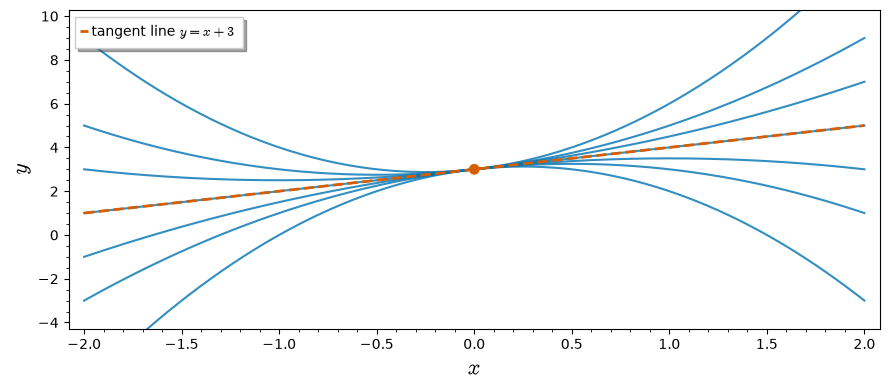

In [1]:
x = SR.var('x')
singular_plot = Graphics()
for c in [-2, -1, -1/2, 0, 1/2, 1, 2]:
    singular_plot += plot(c*x**2 + x + 3, (x, -2, 2), color='#0072B2', thickness=1.5, alpha=0.8)
singular_plot += plot(x + 3, (x, -2, 2), color='#D55E00', linestyle='--', thickness=2,
                      legend_label='tangent line $y = x + 3$')
singular_plot += point((0, 3), color='#D55E00', size=60, zorder=5)
singular_plot.show(xmin=-2, xmax=2, ymin=-4, ymax=10, figsize=[9, 4], frame=True, axes=False,
                   axes_labels=['$x$', '$y$'], legend_options={'loc': 'upper left'})

**Read the picture:** every parabola $y = cx^2 + x + 3$ passes through $(0, 3)$ with slope $1$,  
tangent to the dashed line.  
The data $y(0) = 3$, $y'(0) = 1$ cannot tell them apart.  
On $(0, \infty)$ the theorem applies again: prescribing $y(1)$ and $y'(1)$ selects exactly one solution.  
All the trouble is concentrated at the singular point $x = 0$.

### Boundary value problems

A **boundary value problem** prescribes conditions at two or more points, for example
$$ a_2(x) y'' + a_1(x) y' + a_0(x) y = g(x), \qquad y(a) = y_0, \qquad y(b) = y_1. $$
Other pairs, such as $y'(a) = y_0$ and $y(b) = y_1$, are also common.  
Even when every hypothesis of the theorem holds,  
a boundary value problem may have many solutions, exactly one, or none.

### Example 3: many, one, or no solutions

The functions $\cos(4t)$ and $\sin(4t)$ solve $x'' + 16x = 0$;  
in 4.3 we will see that every solution has the form
$$ x(t) = c_1 \cos(4t) + c_2 \sin(4t). $$
In each problem below, $x(0) = 0$ forces $c_1 = 0$, leaving $x = c_2 \sin(4t)$.

| Second condition | Requirement on $c_2$ | Solutions |
|---|---|---|
| $x(\pi/2) = 0$ | $c_2 \sin(2\pi) = 0$ | infinitely many |
| $x(\pi/8) = 0$ | $c_2 \sin(\pi/2) = 0$ | only $x = 0$ |
| $x(\pi/2) = 1$ | $c_2 \sin(2\pi) = 1$ | none |

With general data $x(0) = \alpha$ and $x(T) = \beta$, the conditions form a linear system:
$$ \begin{pmatrix} 1 & 0 \\ \cos(4T) & \sin(4T) \end{pmatrix}
\begin{pmatrix} c_1 \\ c_2 \end{pmatrix} = \begin{pmatrix} \alpha \\ \beta \end{pmatrix}. $$
If $\sin(4T) \ne 0$, there is exactly one solution for every $\alpha$ and $\beta$.  
If $\sin(4T) = 0$, the matrix is singular:  
there are infinitely many solutions when $\beta = \alpha\cos(4T)$, and none otherwise.  
This is the same alternative as for a square system $M\mathbf c = \mathbf b$.

The exceptional lengths $T = k\pi/4$ are where a nonzero solution vanishes at both ends.  
Such eigenvalue problems are behind the Fourier series of Chapters 11 and 12.

#### Picture: which boundary points can be reached?

In [2]:
t = SR.var('t')
bvp_plot = Graphics()
for c2 in [-2, -1, -1/2, 1/2, 1, 2]:
    bvp_plot += plot(c2*sin(4*t), (t, 0, pi/2), color='#0072B2', thickness=1.5, alpha=0.7)
bvp_plot += line([(pi/8, -2.2), (pi/8, 2.2)], color='gray', linestyle=':')
bvp_targets = [((0, 0), 'black', '$x(0) = 0$'),
               ((pi/2, 0), '#009E73', r'$x(\pi/2) = 0$: every curve'),
               ((pi/8, 0), '#CC79A7', r'$x(\pi/8) = 0$: only $c_2 = 0$'),
               ((pi/2, 1), '#D55E00', r'$x(\pi/2) = 1$: no curve')]
for target, color, label in bvp_targets:
    bvp_plot += point(target, color=color, size=80, zorder=5, legend_label=label)

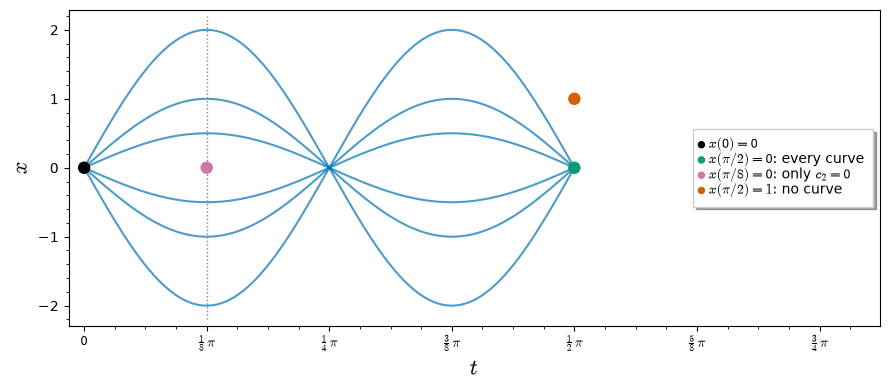

In [3]:
bvp_plot.show(xmin=0, xmax=2.5, ymin=-2.2, ymax=2.2, figsize=[9, 4], frame=True, axes=False,
              ticks=[pi/8, 1], tick_formatter=[pi, None], axes_labels=['$t$', '$x$'],
              legend_options={'loc': 'center right'})

**Read the picture:** every curve $x = c_2 \sin(4t)$ returns to zero at $t = \pi/2$,  
so the green point is reached by all of them and the orange point by none.  
At $t = \pi/8$ the curves are spread out to the heights $c_2$,  
so the purple point is reached only by $c_2 = 0$.  
An initial value problem never has this difficulty: we choose the starting slope directly.

### Differential operators

Write $D y = dy/dx$ and $D^k y = d^k y/dx^k$.  
A polynomial in $D$ with coefficient functions is again an operator:
$$ L = a_n(x) D^n + a_{n - 1}(x) D^{n - 1} + \cdots + a_1(x) D + a_0(x). $$
For example, $y'' + 5y' + 6y = 5x - 3$ reads $(D^2 + 5D + 6) y = 5x - 3$.  
Every linear equation becomes
$$ L y = 0 \qquad\text{or}\qquad L y = g(x). $$

The operator $L$ is **linear**: for functions $f$, $h$ and constants $\alpha$, $\beta$,
$$ \boxed{L(\alpha f + \beta h) = \alpha L f + \beta L h.} $$
This follows from $D(\alpha f + \beta h) = \alpha D f + \beta D h$,  
applied to every power of $D$ and multiplied by the coefficient functions.  
All of 4.1 follows from this identity together with the existence and uniqueness theorem.

### Superposition principle

**Theorem (superposition, homogeneous equations).**  
If $y_1, \ldots, y_k$ solve $L y = 0$ on $I$, then so does every linear combination
$$ y = c_1 y_1 + c_2 y_2 + \cdots + c_k y_k. $$
**Proof.** $L(c_1 y_1 + \cdots + c_k y_k) = c_1 L y_1 + \cdots + c_k L y_k = 0$. $\blacksquare$

In particular, a constant multiple of a solution is a solution,  
and $y = 0$ always solves a homogeneous linear equation.

### Example 4: superposition on $(0, \infty)$

On $(0, \infty)$, both $y_1 = x^2$ and $y_2 = x^2 \ln x$ solve
$$ x^3 y''' - 2xy' + 4y = 0. $$
For $y_2$: $y_2' = 2x\ln x + x$, $y_2'' = 2\ln x + 3$, and $y_2''' = 2/x$, so
$$ x^3 \cdot \frac2x - 2x(2x\ln x + x) + 4x^2 \ln x = 0. $$
Therefore $y = c_1 x^2 + c_2 x^2 \ln x$ is a solution for all constants $c_1$ and $c_2$.

Superposition fails for nonhomogeneous equations:  
if $L y_1 = g$ and $L y_2 = g$, then $L(y_1 + y_2) = 2g$.  
It also fails for nonlinear equations.  
For example, $y = 1/x$ solves $y' = -y^2$, but $y = 2/x$ does not:  
its derivative is $-2/x^2$, while $-y^2 = -4/x^2$.

### The solution set is a vector space

Superposition says that the solutions of $L y = 0$ on $I$ form a vector space:  
a subspace of the functions on $I$, closed under addition and scalar multiplication.  
This was the starting point of the 0923 homework for $y'' + cy = 0$.  
The natural questions now come from linear algebra:  
what is the dimension of this space, and how do we recognize a basis?

### Linear dependence and independence

Functions $f_1, \ldots, f_n$ are **linearly dependent** on $I$  
if there are constants $c_1, \ldots, c_n$, not all zero, such that
$$ c_1 f_1(x) + c_2 f_2(x) + \cdots + c_n f_n(x) = 0 \qquad \text{for every } x \text{ in } I. $$
Otherwise they are **linearly independent**:  
the only such constants are $c_1 = c_2 = \cdots = c_n = 0$.

For two functions, dependence means that one is a constant multiple of the other.

- $\sin(2x)$ and $\sin(x)\cos(x)$ are dependent on $\mathbb R$, since $\sin(2x) = 2\sin(x)\cos(x)$.
- $x$ and $|x|$ are independent on $\mathbb R$:  
  $|x| = x$ for $x > 0$ but $|x| = -x$ for $x < 0$, so no single constant works.
- On $(0, \infty)$ the same two functions are dependent, since $|x| = x$ there.

Dependence is a property of the functions **and** of the interval.

### Examples 5 and 6: dependence among several functions

On $(-\pi/2, \pi/2)$, the functions $\cos(x)^2$, $\sin(x)^2$, $\sec(x)^2$, $\tan(x)^2$ are dependent:
$$ \cos(x)^2 + \sin(x)^2 - \sec(x)^2 + \tan(x)^2 = 0. $$
On $(0, \infty)$, the functions $\sqrt x + 5$, $\sqrt x + 5x$, $x - 1$, $x^2$ are dependent:
$$ \sqrt x + 5x = (\sqrt x + 5) + 5(x - 1) + 0 \cdot x^2. $$
A set of functions is dependent exactly when one of them is a linear combination of the others.

### The Wronskian

How can we test independence without guessing constants?  
Suppose $c_1 f_1 + \cdots + c_n f_n = 0$ on $I$.  
Differentiating $n - 1$ times shows that, at each $x$, the constants satisfy
$$ \begin{pmatrix} f_1 & f_2 & \cdots & f_n \\ f_1' & f_2' & \cdots & f_n' \\
\vdots & \vdots & & \vdots \\ f_1^{(n - 1)} & f_2^{(n - 1)} & \cdots & f_n^{(n - 1)} \end{pmatrix}
\begin{pmatrix} c_1 \\ c_2 \\ \vdots \\ c_n \end{pmatrix} = \mathbf 0. $$

The determinant of this matrix is the **Wronskian** $W(f_1, \ldots, f_n)(x)$.  
If $W(x_0) \ne 0$ at even one point $x_0$, the system forces $c_1 = \cdots = c_n = 0$.  
Hence
$$ \boxed{W(x_0) \ne 0 \text{ for some } x_0 \in I \quad\Longrightarrow\quad
f_1, \ldots, f_n \text{ are independent on } I.} $$

The converse fails for general functions.  
For $f_1 = x^3$ and $f_2 = |x|^3$, we have $f_2' = 3x|x|$ and
$$ W = x^3 \cdot 3x|x| - 3x^2 \cdot |x|^3 = 3x^2|x|(x^2 - |x|^2) = 0 $$
for every $x$, yet the two functions are independent on $\mathbb R$, just like $x$ and $|x|$.  
For **solutions of one linear equation**, however, the converse holds.

### Wronskians of solutions

**Theorem (criterion for independent solutions).**  
Let $y_1, \ldots, y_n$ be solutions of the homogeneous equation $L y = 0$ on $I$,  
under the standing assumptions. Then
$$ \boxed{y_1, \ldots, y_n \text{ are independent on } I \quad\Longleftrightarrow\quad
W(y_1, \ldots, y_n)(x) \ne 0 \text{ for every } x \in I.} $$
In particular, the Wronskian of $n$ solutions is either zero everywhere on $I$ or zero nowhere.

**Proof of the missing direction.**  
Suppose $W(x_0) = 0$ at some $x_0$.  
Then the matrix above has a nonzero null vector $(c_1, \ldots, c_n)$ at $x_0$.  
The combination $y = c_1 y_1 + \cdots + c_n y_n$ solves $L y = 0$, and
$$ y(x_0) = y'(x_0) = \cdots = y^{(n - 1)}(x_0) = 0. $$
As in Example 1, uniqueness gives $y = 0$ on all of $I$, so the solutions are dependent. $\blacksquare$

The pair $x^3$, $|x|^3$ does not contradict the theorem.  
Both functions solve
$$ x^2 y'' - 4xy' + 6y = 0, $$
but the leading coefficient $x^2$ vanishes at $x = 0$.  
On $(0, \infty)$ or on $(-\infty, 0)$, where the theorem applies, the two functions are dependent.

### Abel's formula

For a second-order equation in standard form
$$ y'' + P(x) y' + Q(x) y = 0, $$
the Wronskian $W = y_1 y_2' - y_1' y_2$ of two solutions satisfies
$$ W' = y_1 y_2'' - y_1'' y_2 = y_1(-Py_2' - Qy_2) - (-Py_1' - Qy_1)y_2 = -PW. $$
This first-order linear equation gives **Abel's formula**
$$ \boxed{W(x) = W(x_0) \exp\left(-\int_{x_0}^x P(s)\,ds\right).} $$

The exponential never vanishes,  
which explains again why $W$ is either zero everywhere or zero nowhere.  
For an $n$th-order equation in standard form,  
the same argument gives $W' = -p_{n - 1}(x) W$.  
Abel's formula tells us the Wronskian before we know any solution.

#### Picture: the Wronskian is an area

Represent each solution by its state $(y, y')$, as in the 0923 homework.  
Then $W = y_1 y_2' - y_1' y_2$ is the signed area of the parallelogram  
spanned by the state vectors $(y_1, y_1')$ and $(y_2, y_2')$.  
Follow the states of
$$ y'' + 0.5y' + 4y = 0 $$
that start at $(1, 0)$ and $(0, 1)$, so that $W(0) = 1$.

In [4]:
import numpy as np
from scipy.integrate import odeint
abel_P, abel_Q = float(0.5), float(4)
def abel_rhs(state, t):
    y, v = state
    return [v, -abel_P*v - abel_Q*y]
abel_times = np.linspace(0, 2.4, 241)
abel_y1 = odeint(abel_rhs, [1.0, 0.0], abel_times)    # rows are states (y1, y1')
abel_y2 = odeint(abel_rhs, [0.0, 1.0], abel_times)    # rows are states (y2, y2')
abel_W = abel_y1[:, 0]*abel_y2[:, 1] - abel_y1[:, 1]*abel_y2[:, 0]

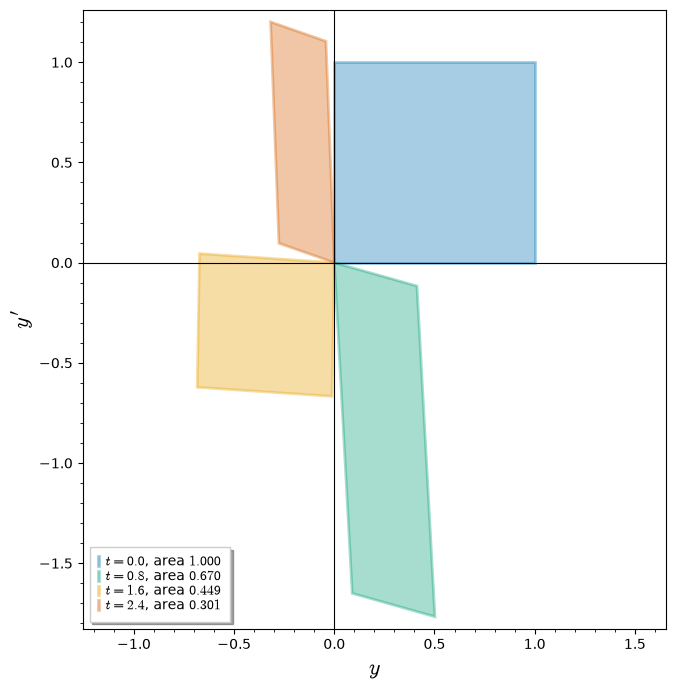

In [5]:
abel_plot = Graphics()
abel_colors = ['#0072B2', '#009E73', '#E69F00', '#D55E00']
for k, color in zip([0, 80, 160, 240], abel_colors):
    v1, v2 = [tuple(map(float, v)) for v in (abel_y1[k], abel_y2[k])]
    corner = (v1[0] + v2[0], v1[1] + v2[1])
    abel_plot += polygon([(0, 0), v1, corner, v2], color=color, alpha=0.35, edgecolor=color,
                         thickness=2, legend_label=f'$t = {abel_times[k]:.1f}$, area ${abel_W[k]:.3f}$')
abel_plot.show(xmin=-1.2, xmax=1.6, aspect_ratio=1, figsize=[7, 7], frame=True, axes=True,
               axes_labels=['$y$', "$y'$"], legend_options={'loc': 'lower left'})

**Read the picture:** the unit square of initial states is carried to parallelograms  
that rotate, shear, and shrink.  
Their areas are $e^{-0.5t}$: $1$, $0.670$, $0.449$, and $0.301$.  
The coefficient $Q = 4$ changes the shape but never the area; only $P$ does.  
For the LRC circuit, $P = R/L$: resistance shrinks areas, and without resistance areas are conserved.

### Fundamental sets of solutions

A set of $n$ linearly independent solutions of an $n$th-order homogeneous linear equation on $I$  
is a **fundamental set of solutions** on $I$.

**Theorem.** A fundamental set always exists.  
If $y_1, \ldots, y_n$ is a fundamental set, then every solution of $L y = 0$ on $I$ is
$$ \boxed{y = c_1 y_1(x) + c_2 y_2(x) + \cdots + c_n y_n(x)} $$
for suitable constants. This is the **general solution** of $L y = 0$ on $I$.

### Why exactly $n$ solutions

Fix $x_0$ in $I$ and send each solution to its initial data:
$$ \Phi : y \longmapsto \bigl(y(x_0), y'(x_0), \ldots, y^{(n - 1)}(x_0)\bigr) \in \mathbb R^n. $$
The map $\Phi$ is linear.  
Existence says that $\Phi$ is onto: every vector of initial data is reached.  
Uniqueness says that $\Phi$ is one-to-one: only $y = 0$ has zero data.  
Therefore $\Phi$ is an isomorphism, and
$$ \boxed{\dim\{y : L y = 0 \text{ on } I\} = n.} $$

Everything else is linear algebra in $\mathbb R^n$.

- Solutions are independent exactly when their initial-data vectors are independent.
- The Wronskian at $x_0$ is the determinant with those vectors as columns.
- The solutions with initial data $\mathbf e_1, \ldots, \mathbf e_n$ form a fundamental set,  
  which proves existence.
- Any $n$ independent solutions form a basis, so every solution is their combination.

Concretely, for $n = 2$, a solution $Y$ is matched by solving
$$ \begin{pmatrix} y_1(x_0) & y_2(x_0) \\ y_1'(x_0) & y_2'(x_0) \end{pmatrix}
\begin{pmatrix} C_1 \\ C_2 \end{pmatrix} = \begin{pmatrix} Y(x_0) \\ Y'(x_0) \end{pmatrix}. $$
The determinant is $W(x_0) \ne 0$, so $C_1$ and $C_2$ exist.  
Then $Y$ and $C_1 y_1 + C_2 y_2$ have the same initial data,  
and uniqueness gives $Y = C_1 y_1 + C_2 y_2$ on all of $I$.

### Example 7: $y'' - 9y = 0$

Both $y_1 = e^{3x}$ and $y_2 = e^{-3x}$ solve $y'' - 9y = 0$ on $\mathbb R$, and
$$ W(e^{3x}, e^{-3x}) = \det\begin{pmatrix} e^{3x} & e^{-3x} \\ 3e^{3x} & -3e^{-3x} \end{pmatrix} = -6 \ne 0. $$
They form a fundamental set, and the general solution is
$$ \boxed{y = c_1 e^{3x} + c_2 e^{-3x}.} $$
As Abel's formula predicts for $P = 0$, the Wronskian is constant.

### Example 8: another basis for the same solutions

The function $y = 4\sinh(3x) - 5e^{-3x}$ also solves $y'' - 9y = 0$,  
so it must belong to the family above.  
Indeed, $\sinh(3x) = (e^{3x} - e^{-3x})/2$ gives
$$ 4\sinh(3x) - 5e^{-3x} = 2e^{3x} - 7e^{-3x}, $$
that is, $c_1 = 2$ and $c_2 = -7$.

The pair $\cosh(3x)$, $\sinh(3x)/3$ is another fundamental set.  
Its initial data at $x_0 = 0$ are $(1, 0)$ and $(0, 1)$, the standard basis,  
so the solution with $y(0) = y_0$ and $y'(0) = y_1$ is simply
$$ y = y_0 \cosh(3x) + \frac{y_1}{3}\sinh(3x). $$
Different fundamental sets describe the same plane of solutions in different coordinates.

### Example 9: a third-order equation

The functions $e^x$, $e^{2x}$, $e^{3x}$ solve $y''' - 6y'' + 11y' - 6y = 0$, and
$$ W = \det\begin{pmatrix} e^x & e^{2x} & e^{3x} \\ e^x & 2e^{2x} & 3e^{3x} \\ e^x & 4e^{2x} & 9e^{3x} \end{pmatrix}
= e^{6x}\det\begin{pmatrix} 1 & 1 & 1 \\ 1 & 2 & 3 \\ 1 & 4 & 9 \end{pmatrix} = 2e^{6x} \ne 0. $$
So the general solution is
$$ \boxed{y = c_1 e^x + c_2 e^{2x} + c_3 e^{3x}.} $$
Abel's formula with $p_2 = -6$ predicts $W = Ce^{6x}$.

### Nonhomogeneous equations

A **particular solution** $y_p$ of $L y = g$ is any single solution, with no arbitrary constants.  
For instance, $y_p = 3$ solves $y'' + 9y = 27$.

**Theorem (general solution, nonhomogeneous equations).**  
Let $y_p$ be a particular solution of $L y = g$ on $I$,  
and let $y_1, \ldots, y_n$ be a fundamental set for $L y = 0$ on $I$.  
Then every solution of $L y = g$ on $I$ is
$$ \boxed{y = c_1 y_1 + \cdots + c_n y_n + y_p.} $$

**Proof.** If $Y$ is any solution, then
$$ L(Y - y_p) = L Y - L y_p = g - g = 0, $$
so $Y - y_p$ solves the homogeneous equation and is a combination of $y_1, \ldots, y_n$. $\blacksquare$

The homogeneous part $y_c = c_1 y_1 + \cdots + c_n y_n$ is the **complementary function**, and
$$ \boxed{y = y_c + y_p.} $$
This is the structure $y = y_h + y_p$ of first-order linear equations in 2.3.

### Example 10: complementary function plus particular solution

Substitution shows that $y_p = -\frac{11}{12} - \frac12 x$ solves
$$ y''' - 6y'' + 11y' - 6y = 3x: $$
only the last two terms contribute, and $11 \cdot (-\frac12) - 6(-\frac{11}{12} - \frac12 x) = 3x$.  
With the fundamental set of Example 9, the general solution is
$$ \boxed{y = c_1 e^x + c_2 e^{2x} + c_3 e^{3x} - \frac{11}{12} - \frac12 x.} $$

### A dictionary with linear algebra

| Matrix equation $M\mathbf c = \mathbf b$ | Linear differential equation $L y = g$ |
|---|---|
| null space of $M$ | solutions of $L y = 0$ |
| basis of the null space | fundamental set of solutions |
| $\mathbf c = \mathbf c_h + \mathbf c_p$ | $y = y_c + y_p$ |
| determinant of the columns | Wronskian |
| singular square $M$: no solution or infinitely many | boundary value problem: none or infinitely many |

The new ingredient is the dimension count:  
$\dim = n$ comes from existence and uniqueness, not from row reduction.

### Superposition for nonhomogeneous equations

**Theorem.** If $L y_{p_i} = g_i$ for $i = 1, \ldots, k$, then
$$ \boxed{L(y_{p_1} + \cdots + y_{p_k}) = g_1 + \cdots + g_k.} $$
More generally, $c_1 y_{p_1} + \cdots + c_k y_{p_k}$ is a particular solution for the input $c_1 g_1 + \cdots + c_k g_k$.  
Split a complicated right-hand side into simple pieces and solve for each piece separately.  
This is the starting point of the method of undetermined coefficients in 4.4.

### Example 11: splitting the input

For $L = D^2 - 3D + 4$, direct substitution gives
$$ L(-4x^2) = -16x^2 + 24x - 8, \qquad L(e^{2x}) = 2e^{2x}, \qquad L(xe^x) = 2xe^x - e^x. $$
Therefore
$$ y_p = -4x^2 + e^{2x} + xe^x $$
is a particular solution of
$$ y'' - 3y' + 4y = -16x^2 + 24x - 8 + 2e^{2x} + 2xe^x - e^x. $$

### Linear systems: state, input, and response

In engineering language, $L y = g(t)$ is an $n$th-order **linear system**.

- The **state** at time $t$ is $\bigl(y(t), y'(t), \ldots, y^{(n - 1)}(t)\bigr)$.
- The **input**, or forcing, is $g(t)$.
- The **output**, or response, is the solution $y(t)$.

By the existence and uniqueness theorem,  
the input together with the initial state determines the response.

Linearity splits every response into two parts:
$$ \boxed{y = y_{\mathrm{zi}} + y_{\mathrm{zs}}.} $$
The **zero-input response** $y_{\mathrm{zi}}$ solves $L y = 0$ with the given initial state.  
The **zero-state response** $y_{\mathrm{zs}}$ solves $L y = g$ starting from rest, with all initial data zero.  
For a damped system $y_{\mathrm{zi}}$ fades away, like the transient terms of 2.3.  
From rest, the response to a sum of inputs is the sum of the responses.

#### Simulation: the response to a sum of inputs

Drive a damped oscillator from rest,
$$ y'' + 0.5y' + 4y = g(t), \qquad y(0) = y'(0) = 0, $$
with a constant push $g_1 = 2$ and a periodic push $g_2 = \cos(1.5t)$.  
Integrate the responses to $g_1$, to $g_2$, and to $g_1 + g_2$ numerically,  
and compare the last one with the sum of the first two.

In [6]:
sup_times = np.linspace(0, 20, 2001)
sup_damping, sup_stiffness, sup_frequency = float(0.5), float(4), float(1.5)
sup_inputs = [('$g_1$', lambda t: 2.0), ('$g_2$', lambda t: np.cos(sup_frequency*t)),
              ('$g_1 + g_2$', lambda t: 2.0 + np.cos(sup_frequency*t))]
def forced_rhs(state, t, g, restoring):
    y, v = state
    return [v, float(g(t)) - sup_damping*v - sup_stiffness*restoring(y)]
def responses(restoring):
    return [odeint(forced_rhs, [0.0, 0.0], sup_times, args=(g, restoring), hmax=0.01)[:, 0]
            for _, g in sup_inputs]

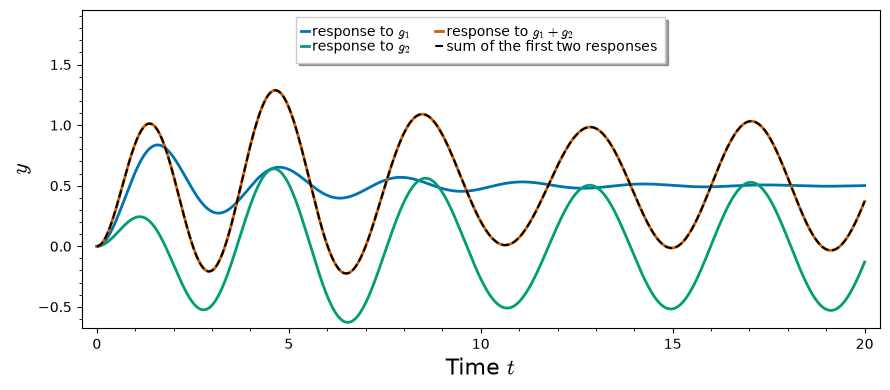

In [7]:
def superposition_plot(curves, ylabel, ymax):
    result = Graphics()
    for (label, _), curve, color in zip(sup_inputs, curves, ['#0072B2', '#009E73', '#D55E00']):
        result += line(list(zip(sup_times, curve)), color=color, thickness=2,
                       legend_label='response to ' + label)
    result += line(list(zip(sup_times, curves[0] + curves[1])), color='black', linestyle='--',
                   thickness=1.5, legend_label='sum of the first two responses')
    result.show(xmin=0, xmax=20, ymax=ymax, figsize=[9, 4], frame=True, axes=False,
                axes_labels=['Time $t$', ylabel], legend_options={'loc': 'upper center', 'ncol': 2})
superposition_plot(responses(lambda y: y), '$y$', ymax=1.9)

**Read the picture:** the dashed black curve, the sum of the blue and green responses,  
lies exactly on the orange response to the combined input.  
The blue response settles at $g_1/4 = 0.5$, and the green one oscillates at the input frequency $1.5$.  
Neither response needs to be recomputed when the inputs are combined.

#### Simulation: a pendulum breaks superposition

A pendulum with friction, driven by a torque $g(t)$, obeys the nonlinear equation
$$ \theta'' + 0.5\theta' + 4\sin\theta = g(t), \qquad \theta(0) = \theta'(0) = 0. $$
For small angles $\sin\theta \approx \theta$, and the equation is close to the oscillator above.  
Repeat the experiment with the same inputs, which swing the pendulum past $90^\circ$.

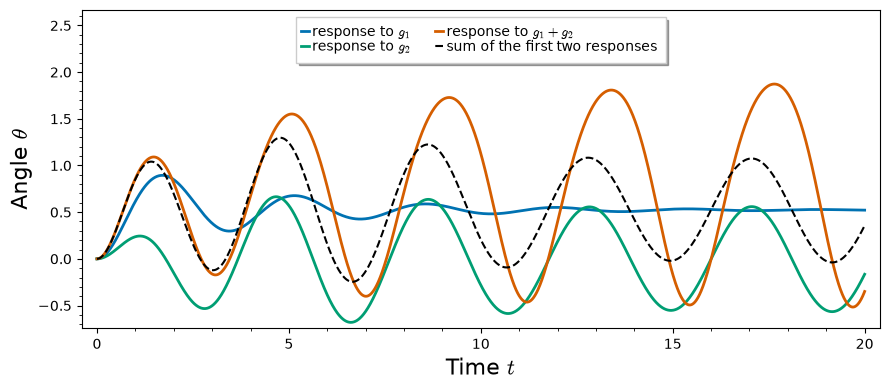

In [8]:
superposition_plot(responses(np.sin), r'Angle $\theta$', ymax=2.6)

**Read the picture:** the dashed sum no longer follows the orange response.  
The constant torque alone holds the pendulum near $\arcsin(1/2) \approx 0.52$ rad,  
close to the linear value $0.5$,  
but the combined input swings it much farther than the sum predicts.  
For a nonlinear equation there is no $y_c + y_p$ structure,  
and responses must be recomputed for every input.

## 4.2 Reduction of Order

### One solution gives a second

A second-order homogeneous linear equation needs two independent solutions.  
In 4.3, constant coefficients sometimes produce only one exponential solution $y_1$.  
If one nonzero solution $y_1$ is known, look for a second solution in the form
$$ y_2 = u(x) y_1(x). $$
The quotient $u = y_2/y_1$ must be nonconstant, since $y_1$ and $y_2$ are independent.  
Substituting $y = uy_1$ produces a first-order linear equation for $w = u'$:  
the order is reduced from two to one.

### Example 1: $y'' - y = 0$ with $y_1 = e^x$

Put $y = ue^x$. The product rule gives
$$ y' = (u' + u)e^x, \qquad y'' = (u'' + 2u' + u)e^x, $$
so
$$ y'' - y = (u'' + 2u')e^x = 0. $$
The term with $u$ itself cancels because $y_1$ is a solution.  
With $w = u'$, we get the first-order linear equation $w' + 2w = 0$.

Hence $w = c_1 e^{-2x}$, and integrating again,
$$ u = -\frac{c_1}{2}e^{-2x} + c_2, \qquad y = ue^x = -\frac{c_1}{2}e^{-x} + c_2 e^x. $$
Choosing $c_1 = -2$ and $c_2 = 0$ gives the second solution $y_2 = e^{-x}$.  
Since $W(e^x, e^{-x}) = -2 \ne 0$, the formula for $y$ is already the general solution.

### The general case

Write the equation in standard form,
$$ y'' + P(x) y' + Q(x) y = 0, $$
and suppose $y_1$ is a solution with $y_1(x) \ne 0$ on $I$.  
For $y = uy_1$,
$$ y'' + Py' + Qy = u\underbrace{(y_1'' + Py_1' + Qy_1)}_{= 0} + y_1 u'' + (2y_1' + Py_1)u'. $$

With $w = u'$, the equation becomes
$$ y_1 w' + (2y_1' + Py_1)w = 0, $$
which is both linear and separable:
$$ \frac{dw}{w} + 2\frac{y_1'}{y_1}\,dx + P\,dx = 0, \qquad \ln|wy_1^2| = -\int P\,dx + c. $$
Thus $w = c_1 e^{-\int P\,dx}/y_1^2$.

Integrate once more and choose $c_1 = 1$, $c_2 = 0$:
$$ \boxed{y_2 = y_1(x)\int\frac{e^{-\int P(x)\,dx}}{y_1(x)^2}\,dx.} $$
Any antiderivatives may be used;  
other choices only rescale $y_2$ or add a multiple of $y_1$.

### Why the formula works: the Wronskian again

The quotient rule gives
$$ \left(\frac{y_2}{y_1}\right)' = \frac{y_1 y_2' - y_1' y_2}{y_1^2} = \frac{W(y_1, y_2)}{y_1^2}. $$
By Abel's formula, the Wronskian of any two solutions is $W = Ce^{-\int P\,dx}$.  
So the reduction-of-order formula is Abel's formula plus the quotient rule:
$$ \boxed{u' = \frac{W}{y_1^2}, \qquad W = e^{-\int P\,dx} \ne 0.} $$
In particular, $y_1$ and $y_2$ are automatically independent.

### Example 2: $x^2 y'' - 3xy' + 4y = 0$ with $y_1 = x^2$

On $(0, \infty)$, the standard form is
$$ y'' - \frac3x y' + \frac4{x^2} y = 0, \qquad P(x) = -\frac3x. $$
Then $e^{-\int P\,dx} = e^{3\ln x} = x^3$, and
$$ y_2 = x^2 \int\frac{x^3}{x^4}\,dx = x^2 \int\frac{dx}{x} = x^2 \ln x. $$
The general solution on $(0, \infty)$ is
$$ \boxed{y = c_1 x^2 + c_2 x^2 \ln x.} $$

### Example 3: where $xe^{mx}$ comes from

For $y'' - 4y' + 4y = 0$, substitution shows that $y_1 = e^{2x}$ is a solution.  
Here $P = -4$, so $e^{-\int P\,dx} = e^{4x}$ and
$$ y_2 = e^{2x}\int\frac{e^{4x}}{e^{4x}}\,dx = xe^{2x}. $$
The general solution is $y = c_1 e^{2x} + c_2 xe^{2x}$.  
The same computation for $y'' - 2my' + m^2 y = 0$ gives $e^{mx}$ and $xe^{mx}$;  
this is where the factor $x$ in the repeated-root case of 4.3 comes from.

### Example 4: Legendre's equation with $n = 1$

The polynomial $y_1 = x$ solves Legendre's equation
$$ (1 - x^2) y'' - 2xy' + 2y = 0, $$
which arises in problems with spherical symmetry. Its singular points are $x = \pm1$.  
On $0 < x < 1$, where $y_1 \ne 0$,
$$ P(x) = -\frac{2x}{1 - x^2}, \qquad e^{-\int P\,dx} = e^{-\ln(1 - x^2)} = \frac{1}{1 - x^2}. $$

Partial fractions give
$$ y_2 = x\int\frac{dx}{x^2(1 - x^2)} = x\int\left(\frac{1}{x^2} + \frac{1}{1 - x^2}\right)dx
= x\left(-\frac1x + \frac12\ln\frac{1 + x}{1 - x}\right). $$
Therefore
$$ \boxed{y_2 = \frac x2\ln\frac{1 + x}{1 - x} - 1.} $$
The derivation needed $x > 0$, but the result solves the equation on all of $(-1, 1)$.

#### Picture: only the polynomial solution stays bounded

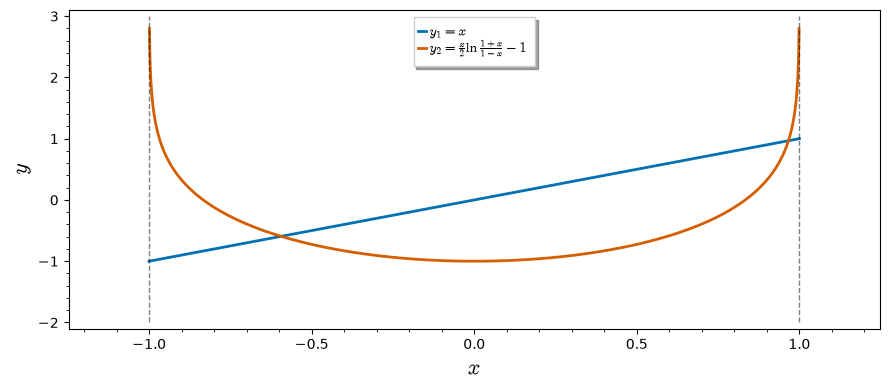

In [9]:
legendre_y2 = x/2*log((1 + x)/(1 - x)) - 1
legendre_plot = plot(x, (x, -1, 1), color='#0072B2', thickness=2, legend_label='$y_1 = x$')
legendre_plot += plot(legendre_y2, (x, -0.999, 0.999), color='#D55E00', thickness=2,
                      legend_label=r'$y_2 = \frac{x}{2}\ln\frac{1 + x}{1 - x} - 1$')
for side in [-1, 1]:
    legendre_plot += line([(side, -2), (side, 3)], color='black', linestyle='--', alpha=0.5)
legendre_plot.show(xmin=-1.2, xmax=1.2, ymin=-2, ymax=3, figsize=[9, 4], frame=True, axes=False,
                   axes_labels=['$x$', '$y$'], legend_options={'loc': 'upper center'})

**Read the picture:** $y_1$ is odd and $y_2$ is even, so the two are clearly independent.  
The second solution is smooth through $x = 0$ but blows up at the singular points $x = \pm1$,  
where the leading coefficient $1 - x^2$ vanishes; the Wronskian $1/(1 - x^2)$ blows up there too.  
Every solution $c_1 x + c_2 y_2$ with $c_2 \ne 0$ is unbounded on $(-1, 1)$.  
This is why bounded physical problems on a sphere select the polynomial solution.

### Reduction of order with a right-hand side

The same substitution works for a nonhomogeneous equation.  
If $y_1$ solves the homogeneous equation, then $y = uy_1$ turns
$$ y'' + P(x) y' + Q(x) y = f(x) $$
into the first-order linear equation
$$ y_1 w' + (2y_1' + Py_1)w = f, \qquad w = u'. $$
One computation produces both a second homogeneous solution and a particular solution.

### Example 5: $y'' - 4y = 2$ with $y_1 = e^{2x}$

Put $y = ue^{2x}$.  
Then $y'' - 4y = (u'' + 4u')e^{2x}$, so with $w = u'$,
$$ w' + 4w = 2e^{-2x}. $$
Use the integrating factor $e^{4x}$:
$$ (e^{4x} w)' = 2e^{2x}, \qquad w = e^{-2x} + c_1 e^{-4x}. $$

Integrate again:
$$ u = -\frac12 e^{-2x} - \frac{c_1}{4}e^{-4x} + c_2, \qquad
y = ue^{2x} = -\frac12 - \frac{c_1}{4}e^{-2x} + c_2 e^{2x}. $$
Read off the particular solution $y_p = -1/2$ and the second solution $y_2 = e^{-2x}$.  
After renaming the constants,
$$ \boxed{y = c_1 e^{2x} + c_2 e^{-2x} - \frac12.} $$

### Summary

| Question | Tool |
|---|---|
| How many solutions are needed for $L y = 0$? | $n$ independent ones; $y = c_1 y_1 + \cdots + c_n y_n$ |
| Are given solutions independent? | Wronskian at one convenient point |
| How does the Wronskian change? | Abel: $W = Ce^{-\int P\,dx}$ |
| How do we solve $L y = g$? | $y = y_c + y_p$; split $g$ by superposition |
| One solution $y_1$ of a second-order equation is known | $y = uy_1$, then $w = u'$ |

### Practice habits for linear theory and reduction of order

- Divide by the leading coefficient before reading off $P(x)$.
- State the interval: avoid zeros of the leading coefficient, and zeros of $y_1$ in reduction of order.
- Check a Wronskian at one convenient point, often $x_0 = 0$ or $x_0 = 1$.
- In reduction of order, the term with $u$ itself always cancels; if it does not, recheck $y_1$.
- Verify the final answer by substitution.

## Checking Worked Solutions with Sage

Sage computes Wronskians, applies the reduction-of-order formula,  
and solves second-order initial value problems.  
As before, a symbolic check confirms the algebra;  
intervals, branches, and singular points still need a separate look.

In [10]:
from IPython.display import display, Math
wronskian_examples = [(exp(3*x), exp(-3*x)), (exp(x), exp(2*x), exp(3*x)),
                      (x**2, x**2*log(x)), (x, legendre_y2), (x**3, abs(x)**3)]
for functions in wronskian_examples:
    W = wronskian(*functions).simplify_full()
    display(Math(r'W\left(' + ', '.join(latex(f) for f in functions) + r'\right) = ' + latex(W)))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

These are Examples 7 and 9, the pairs from Example 4 and Legendre's equation,  
and the pair $x^3$, $|x|^3$.  
The Wronskian $x^3$ agrees with Abel's formula for $P = -3/x$,  
and $-1/(x^2 - 1) = 1/(1 - x^2)$ agrees with Abel's formula for Legendre's equation.

In [11]:
def apply_L(coefficients, y):
    # coefficients = [a_0, a_1, ..., a_n] for a_n y^(n) + ... + a_1 y' + a_0 y
    return sum(a*diff(SR(y), x, k) for k, a in enumerate(coefficients))
c = SR.var('c')
residual_checks = [('4.1 Example 2', [-4, 0, 1], 3*exp(2*x) + exp(-2*x) - 3*x, 12*x),
                   ('singular point', [2, -2*x, x**2], c*x**2 + x + 3, 6),
                   ('4.1 Example 4', [4, -2*x, 0, x**3], x**2*log(x), 0),
                   ('4.1 Example 10', [-6, 11, -6, 1], -11/12 - x/2, 3*x),
                   ('4.1 Example 11', [4, -3, 1], -4*x**2 + exp(2*x) + x*exp(x),
                    -16*x**2 + 24*x - 8 + 2*exp(2*x) + 2*x*exp(x) - exp(x))]

In [12]:
residual_checks += [('4.2 Example 4', [2, -2*x, 1 - x**2], legendre_y2, 0),
                    ('4.2 Example 5', [-4, 0, 1], -1/2 + exp(-2*x), 2)]
for name, coefficients, y, g in residual_checks:
    assert (apply_L(coefficients, y) - g).simplify_full() == 0, name
print('Residuals vanish:', ', '.join(name for name, *_ in residual_checks))

Residuals vanish: 4.1 Example 2, singular point, 4.1 Example 4, 4.1 Example 10, 4.1 Example 11, 4.2 Example 4, 4.2 Example 5


In [13]:
def second_solution(P, y1):
    return (y1*integrate(exp(-integrate(P, x))/y1**2, x)).simplify_full()
reduction_examples = [(0, exp(x)), (-3/x, x**2), (-4, exp(2*x)), (-2*x/(1 - x**2), x)]
assume(x > 0, x < 1)
for P, y1 in reduction_examples:
    display(Math(r'y_1 = ' + latex(y1) + r' \quad\Longrightarrow\quad y_2 = '
                 + latex(second_solution(SR(P), y1))))
forget()

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

The first three agree with Examples 1, 2, and 3 of 4.2, up to a constant factor.  
For Legendre's equation, Sage writes $\log(x - 1)$ without an absolute value.  
On $0 < x < 1$ this branch differs from ours by $i\pi$,  
so its answer is $-y_2$ plus a constant multiple of $y_1 = x$.  
A computer algebra system may drop absolute values; check the interval yourself.

In [14]:
Y = function('Y')(x)
desolve_examples = [diff(Y, x, 2) - 4*Y == 12*x,
                    x**2*diff(Y, x, 2) - 2*x*diff(Y, x) + 2*Y == 6,
                    x**2*diff(Y, x, 2) - 3*x*diff(Y, x) + 4*Y == 0,
                    diff(Y, x, 2) - 4*Y == 2]
display(Math(latex(desolve(desolve_examples[0], Y, ics=[0, 4, 1]))))
for equation in desolve_examples[1:]:
    display(Math(latex(desolve(equation, Y))))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

The first line is Example 2 of 4.1, with its initial data.  
The others are general solutions; Maxima names the arbitrary constants $K_1$ and $K_2$.  
The second line confirms that every solution of $x^2 y'' - 2xy' + 2y = 6$ passes through $(0, 3)$.

## Homework Due Sunday

Each problem asks for one key step.  
Give only the requested interval, relation, or expression;  
do not solve the differential equation.

### Where does the theorem apply?

For A1–A6, write the largest interval containing $x_0$ on which  
the existence and uniqueness theorem guarantees a unique solution.

A1. $(x - 2)y'' + 3y = x$, $y(0) = 0$, $y'(0) = 1$.  
A2. $y'' + (\tan x) y = e^x$, $y(0) = 1$, $y'(0) = 0$.  
A3. $x^2 y'' - 2xy' + 2y = 6$, $y(1) = 3$, $y'(1) = 1$.

A4. $(x^2 - 4) y''' + (\ln x) y' = 0$, $y(1) = y'(1) = y''(1) = 0$.  
A5. The equation of A4 with the same data at $x_0 = 3$.  
A6. $\sin(x) y'' + y = 0$, $y(\pi/2) = 1$, $y'(\pi/2) = 0$.  
A7. Every member of $y = c_1 + c_2 x^2$ solves $xy'' - y' = 0$.  
Explain in one line why no member satisfies $y(0) = 0$, $y'(0) = 1$,  
and name the hypothesis of the theorem that fails.

### Dependent or independent?

For B1–B7, decide whether the functions are linearly independent on $(-\infty, \infty)$.  
If they are dependent, give constants, not all zero, in a dependence relation.

B1. $x$, $x^2$, $4x - 3x^2$.  
B2. $0$, $x$, $e^x$.  
B3. $5$, $\cos(x)^2$, $\sin(x)^2$.  
B4. $\cos(2x)$, $1$, $\cos(x)^2$.

B5. $x$, $x - 1$, $x + 3$.  
B6. $1 + x$, $x$, $x^2$.  
B7. $e^x$, $e^{-x}$, $\sinh x$.  
B8. $x$ and $|x|$, first on $(-\infty, \infty)$ and then on $(0, \infty)$.

### Wronskians only

For C1–C7, compute and simplify the Wronskian only.  
Then say whether the functions are independent on the given interval.

C1. $e^{3x}$, $e^{-4x}$ on $(-\infty, \infty)$.  
C2. $\cosh(2x)$, $\sinh(2x)$ on $(-\infty, \infty)$.  
C3. $e^x \cos(2x)$, $e^x \sin(2x)$ on $(-\infty, \infty)$.  
C4. $e^{x/2}$, $xe^{x/2}$ on $(-\infty, \infty)$.

C5. $x^3$, $x^4$ on $(0, \infty)$.  
C6. $\cos(\ln x)$, $\sin(\ln x)$ on $(0, \infty)$.  
C7. $1$, $x$, $\cos x$, $\sin x$ on $(-\infty, \infty)$.

### Abel's formula without solving

For D1–D5, use Abel's formula to write the Wronskian of two solutions, up to a constant $C$.  
Put each equation in standard form first.

D1. $y'' + 3y' + 2y = 0$.  
D2. $x^2 y'' + xy' - y = 0$ on $(0, \infty)$.  
D3. $(1 - x^2) y'' - 2xy' + 6y = 0$ on $(-1, 1)$.  
D4. $y'' + (\sin x) y' + e^x y = 0$.  
D5. $y'' + Q(x) y = 0$, where $Q$ is any continuous function.

## Homework Due Wednesday

Keep the pieces separate.  
Unless a problem says otherwise, do not find the complete solution.

### Complementary function plus particular solution

E1. The complementary function of $y'' - 7y' + 10y = 24e^x$ is $c_1 e^{2x} + c_2 e^{5x}$,  
and $y_p = 6e^x$. Write the general solution only.  
E2. $y_{p_1} = 3e^{2x}$ solves $y'' - 6y' + 5y = -9e^{2x}$,  
and $y_{p_2} = x^2 + 3x$ solves $y'' - 6y' + 5y = 5x^2 + 3x - 16$.  
Write a particular solution of $y'' - 6y' + 5y = 5x^2 + 3x - 16 - 9e^{2x}$ only.  
E3. With the same $y_{p_1}$ and $y_{p_2}$,  
write a particular solution of $y'' - 6y' + 5y = -10x^2 - 6x + 32 + e^{2x}$ only.

E4. By inspection, write a particular solution of $y'' + 2y = 10$, and one of $y'' + 2y = -4x$.  
E5. Use E4 to write a particular solution of $y'' + 2y = -4x + 10$, and one of $y'' + 2y = 8x + 5$.  
E6. Using $D^n x^{n - 1} = 0$ and $D^n x^n = n!$,  
write the general solutions of $y''' = 0$, $y'' = 2$, and $y^{(4)} = 24$.

### Reduction of order in pieces

In F1–F8, the given $y_1$ solves the equation.  
Write three separate pieces: $P(x)$, the factor $e^{-\int P\,dx}$,  
and the second solution $y_2$ from the reduction-of-order formula.  
You may drop constant factors and multiples of $y_1$ from $y_2$.

F1. $y'' - 4y' + 4y = 0$; $y_1 = e^{2x}$.  
F2. $y'' + 16y = 0$; $y_1 = \cos(4x)$, on $-\pi/8 < x < \pi/8$.  
F3. $y'' - y = 0$; $y_1 = \cosh x$.

F4. $9y'' - 12y' + 4y = 0$; $y_1 = e^{2x/3}$.  
F5. $x^2 y'' - 7xy' + 16y = 0$ on $x > 0$; $y_1 = x^4$.  
F6. $x^2 y'' + 2xy' - 6y = 0$ on $x > 0$; $y_1 = x^2$.  
F7. $xy'' + y' = 0$ on $x > 1$; $y_1 = \ln x$.  
F8. $(1 - 2x - x^2) y'' + 2(1 + x) y' - 2y = 0$ on $-1 < x < \sqrt2 - 1$; $y_1 = x + 1$.

### Reduction of order with a right-hand side

Use $y = uy_1$ and $w = u'$, where $y_1$ solves the associated homogeneous equation.

G1. $y'' + y' = 1$; $y_1 = 1$. Write the first-order equation for $w$ only.  
G2. For G1, write the second solution $y_2$ and a particular solution $y_p$ only.  
G3. $y'' - 3y' + 2y = 5e^{3x}$; $y_1 = e^x$. Write the first-order equation for $w$ only.  
G4. For G3, write the second solution $y_2$ and a particular solution $y_p$ only.

### Put the pieces together

Use the given form; no derivation is needed.

H1. $y = c_1 e^x + c_2 e^{-x}$ solves $y'' - y = 0$.  
Find the member with $y(0) = 0$ and $y'(0) = 1$, and write it with a hyperbolic function.  
H2. $y = c_1 x + c_2 x\ln x$ is the general solution of $x^2 y'' - xy' + y = 0$ on $(0, \infty)$.  
Find the member with $y(1) = 3$ and $y'(1) = -1$.

H3. $y = c_1 e^x \cos x + c_2 e^x \sin x$ is the general solution of $y'' - 2y' + 2y = 0$.  
For each pair of boundary conditions, write "none", "infinitely many",  
or the unique pair $(c_1, c_2)$.

(a) $y(0) = 1$, $y(\pi) = 0$.  
(b) $y(0) = 1$, $y(\pi) = -1$.  
(c) $y(0) = 1$, $y(\pi/2) = 1$.  
(d) $y(0) = 0$, $y(\pi) = 0$.

H4. For $\omega > 0$, $x(t) = c_1 \cos(\omega t) + c_2 \sin(\omega t)$ is the general solution of $x'' + \omega^2 x = 0$.  
Write the member with $x(0) = x_0$ and $x'(0) = x_1$.